# Parte 1: Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

## Configuración inicial

- **Estudiante:** Diego Enrique Sime Rendón (@diegosimemirror).
- **Fecha de extracción del corpus:** 25 de octubre de 2026 (hora de Lima). Las descargas se hicieron con pausas entre solicitudes y quedaron registradas en `datos/raw/logs/`.
- **Corpus A, Documentos (25):** 8 impresos, 8 fotos y 9 manuscritos peruanos de **Wikimedia Commons**. Las licencias son dominio público (PD-old-100, PD-Peru-organization, PD-Peru-1961law), CC0 (Biblioteca Nacional del Perú y Abelchristian111), CC BY 2.0 (Ministerio de Defensa del Perú), CC BY 4.0 y CC BY-SA 3.0/4.0, según la tabla del Proceso 1.
- **Corpus B, Audio (22 clips, 40,9 min):**
  - 20 clips de **OpenSLR 73**, el corpus de español peruano de Google, con licencia **CC BY-SA 4.0**. Cada clip une los enunciados de un mismo hablante, con un hablante distinto por clip.
  - 2 entrevistas de **Wikimedia Commons** (`Entrevista_4.wav` y `Entrevista_1,.wav`, de la UNMSM), con licencia **CC BY-SA 4.0** y autoría de Gianpier Yair Venegas Ambia. Tienen 2 hablantes cada una.
- **Versiones:**
  - **PaddleOCR 3.7.0** (paddlepaddle 3.3.1), con los modelos `PP-OCRv5_mobile_det` + `latin_PP-OCRv5_mobile_rec`, el clasificador de orientación de página y el de orientación de línea.
  - **faster-whisper 1.2.1** con el modelo **`small`** (int8, CPU) y VAD Silero.
  - Diarización con **pyannote.audio 4.0.7** (huellas WeSpeaker ResNet34), usando `voz.py` de la Sesión 13.
- **Entorno:** conda `pucp` (Python 3.12) en una laptop sin GPU utilizable (GTX 1050 sin CUDA instalado). Tiene las mismas librerías que `uv sync --group docai` y `uv sync --group audio`. Todo corre en CPU limitado a 2 núcleos.

## Procesos

0. Comprobar el entorno y las versiones.
1. Inventariar el corpus con sus fuentes y licencias.
2. Limpiar: buscar duplicados por hash y descartar documentos ilegibles o audios sin voz.
3. Extraer texto con OCR (PaddleOCR).
4. Transcribir con ASR (faster-whisper + VAD) y diarizar las entrevistas.
5. Seudonimizar.
6. Hacer el análisis exploratorio (3 gráficos Plotly).
7. Validar con los textos más largos y más cortos.
8. Exportar los CSV, SRT y TXT y armar la muestra publicable.

In [1]:
# PROCESO 0: Comprobar el entorno y registrar versiones.
# Insumo: entorno conda pucp.
# Resultado: versión de Python y de cada librería del pipeline.

# sys: informa qué Python ejecuta el notebook.
import sys
# importlib.metadata: lee la versión instalada de cada paquete sin importarlo.
from importlib.metadata import version

print("Python:", sys.version.split()[0], "|", sys.executable)
for paquete in ["paddleocr", "paddlepaddle", "faster-whisper", "ctranslate2", "pyannote.audio",
                "torch", "rapidfuzz", "pandas", "plotly"]:
    print(f"{paquete:15s} {version(paquete)}")

Python: 3.12.15 | C:\Users\Diego Sime\.conda\envs\pucp\python.exe
paddleocr       3.7.0
paddlepaddle    3.3.1
faster-whisper  1.2.1
ctranslate2     4.8.4
pyannote.audio  4.0.7
torch           2.14.1+cpu
rapidfuzz       3.14.6
pandas          3.0.6
plotly          7.1.0


In [2]:
# PROCESO 0.1: Rutas de trabajo y límites de CPU.
# Insumo: carpeta tarea_2/ como directorio actual.
# Resultado: rutas a los datos crudos (fuera de Git) y a las salidas publicables.

# os: fija variables de entorno antes de cargar los modelos.
import os
# pathlib: arma rutas que funcionan en Windows y Linux.
from pathlib import Path

os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")  # no consultar el servidor de modelos en cada carga
BASE = Path.cwd()
DATOS = BASE / "datos"
RAW = DATOS / "raw"                      # corpus original: no se versiona (.gitignore)
DOCS_RAW = RAW / "documentos"
AUDIO_RAW = RAW / "audio"
SALIDAS_ASR = DATOS / "salidas_asr"      # SRT y TXT ya seudonimizados: sí se versionan
EJEMPLOS = DATOS / "ejemplos"            # muestra ligera y publicable para el dashboard
for carpeta in [SALIDAS_ASR, EJEMPLOS, DOCS_RAW / "preprocesadas", DOCS_RAW / "ocr_paddle", AUDIO_RAW / "salidas"]:
    carpeta.mkdir(parents=True, exist_ok=True)
print(BASE)
print(sorted(p.name for p in RAW.iterdir()))

D:\Mis Documentos\GitHub\Python-Intermedio-QLAB\tarea_2
['INVENTARIO.md', 'audio', 'audio_descargados.csv', 'documentos', 'documentos_descargados.csv', 'documentos_fuente.csv', 'fuentes_descarga.csv', 'llm', 'logs', 'manifest_clips.csv', 'seudonimos.json']


## Proceso 1. Inventario, fuentes y licencias

**Insumo:** los manifiestos de descarga (`documentos_fuente.csv`, `audio_descargados.csv` y `fuentes_descarga.csv`).
**Método:** cruzar cada archivo con su ficha de Commons u OpenSLR y calcular su huella MD5.
**Resultado esperado:** una fila por archivo, con el tipo, la licencia, el tamaño y el hash.

In [3]:
# PROCESO 1: Inventariar el corpus.
# Insumo: archivos en datos/raw/ y los tres manifiestos de descarga.
# Resultado: tablas `docs` (25 filas) y `clips` (22 filas) con fuente, licencia y hash.

# hashlib: calcula la huella MD5 de cada archivo para detectar duplicados exactos.
import hashlib
# pandas: organiza los registros en filas y columnas.
import pandas as pd
# soundfile: lee la duración y el formato de los WAV sin cargarlos completos.
import soundfile as sf

pd.set_option("display.max_colwidth", 90)


def md5(ruta):
    """archivo → huella MD5 (32 caracteres hexadecimales)."""
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


fuentes_descarga = pd.read_csv(RAW / "fuentes_descarga.csv")
docs = pd.read_csv(RAW / "documentos_fuente.csv")
docs["archivo"] = [f"datos/raw/documentos/{i}.jpg" for i in docs["id"]]
docs["fuente"] = "Wikimedia Commons (" + docs["licencia"] + ")"
docs["bytes"] = [(BASE / a).stat().st_size for a in docs["archivo"]]
docs["md5"] = [md5(BASE / a) for a in docs["archivo"]]

clips = pd.read_csv(RAW / "audio_descargados.csv")
clips = clips.merge(fuentes_descarga[["id", "fuente_url", "licencia"]], on="id", how="left")
clips["origen"] = ["OpenSLR 73" if f.startswith("OpenSLR") else "Entrevista UNMSM (Commons)" for f in clips["fuente"]]
info = [sf.info(BASE / a) for a in clips["archivo_audio"]]
clips["duracion_seg"] = [round(i.duration, 2) for i in info]
clips["sr_original"] = [i.samplerate for i in info]
clips["md5"] = [md5(BASE / a) for a in clips["archivo_audio"]]

print("Documentos por tipo:", docs["tipo"].value_counts().to_dict())
print(f"Audio: {len(clips)} clips, {clips['duracion_seg'].sum() / 60:.1f} min")
print(clips.groupby("origen")["duracion_seg"].agg(["count", "sum"]).assign(minutos=lambda d: (d["sum"] / 60).round(1)))
docs[["id", "tipo", "titulo", "licencia"]]

Documentos por tipo: {'manuscrito': 9, 'impreso': 8, 'foto': 8}
Audio: 22 clips, 40.9 min
                            count      sum  minutos
origen                                             
Entrevista UNMSM (Commons)      2   359.93      6.0
OpenSLR 73                     20  2096.30     34.9


,id,tipo,titulo,licencia
0,doc_001,impreso,Variedades No. 0 (Número Prospecto).pdf,PD-Peru-organization
1,doc_002,impreso,Variedades No. 10.pdf,PD-Peru-organization + PD-US
2,doc_003,impreso,Variedades No. 100.pdf,PD-Peru-organization
3,doc_004,impreso,El Comercio Issue 1.jpg,PD-old-100
4,doc_005,impreso,Constitución Política del Perú (1856).pdf,PD-old-100
5,doc_006,impreso,Constitución Política de la República Peruana (1828).pdf,PD-old-100
6,doc_007,impreso,"4000004161-0016 - Carta de Carlos J. Bachmann. 1914 julio 4, Maldonado; para Ricardo P...",CC0 (Biblioteca Nacional del Perú)
7,doc_008,impreso,Carta de César Vallejo a José Carlos Mariátegui.pdf,PD-Peru-1961law
8,doc_009,foto,Carta de Felipe Santiago Salaverry a la seva esposa abans de la seva mort a Arequipa.jpg,CC BY-SA 4.0 (foto: Pitxiquin)
9,doc_010,foto,AAMSM carta a hermano 31072010.jpg,CC BY-SA 3.0 (foto: Dtarazona)


In [4]:
# PROCESO 1.1: Licencias de los audios.
# Insumo: tabla `clips`.
# Resultado: atribución por origen (se repite en el README y en datos/fuentes.csv).
clips[["id", "origen", "licencia", "duracion_seg", "sr_original", "fuente"]]

,id,origen,licencia,duracion_seg,sr_original,fuente
0,clip_001,OpenSLR 73,CC BY-SA 4.0,104.11,48000,"OpenSLR 73 (es_pe_female.zip), hablante pef_06136, 11 enunciados concatenados"
1,clip_002,OpenSLR 73,CC BY-SA 4.0,103.34,48000,"OpenSLR 73 (es_pe_male.zip), hablante pem_07508, 12 enunciados concatenados"
2,clip_003,OpenSLR 73,CC BY-SA 4.0,108.12,48000,"OpenSLR 73 (es_pe_female.zip), hablante pef_08784, 17 enunciados concatenados"
3,clip_004,OpenSLR 73,CC BY-SA 4.0,108.29,48000,"OpenSLR 73 (es_pe_male.zip), hablante pem_08784, 15 enunciados concatenados"
4,clip_005,OpenSLR 73,CC BY-SA 4.0,102.06,48000,"OpenSLR 73 (es_pe_female.zip), hablante pef_01523, 14 enunciados concatenados"
5,clip_006,OpenSLR 73,CC BY-SA 4.0,104.79,48000,"OpenSLR 73 (es_pe_male.zip), hablante pem_07505, 17 enunciados concatenados"
6,clip_007,OpenSLR 73,CC BY-SA 4.0,100.10,48000,"OpenSLR 73 (es_pe_female.zip), hablante pef_03349, 16 enunciados concatenados"
7,clip_008,OpenSLR 73,CC BY-SA 4.0,105.22,48000,"OpenSLR 73 (es_pe_male.zip), hablante pem_03034, 16 enunciados concatenados"
8,clip_009,OpenSLR 73,CC BY-SA 4.0,105.13,48000,"OpenSLR 73 (es_pe_female.zip), hablante pef_02436, 15 enunciados concatenados"
9,clip_010,OpenSLR 73,CC BY-SA 4.0,105.64,48000,"OpenSLR 73 (es_pe_male.zip), hablante pem_07049, 17 enunciados concatenados"


## Proceso 2. Limpieza: duplicados, ilegibles y audios sin voz

**Criterios fijados antes de correr los modelos:**
- **Duplicado:** dos archivos con el mismo MD5.
- **Documento ilegible:** una imagen que no abre o cuyo lado menor mide menos de 300 px. Un documento difícil de leer, como un manuscrito antiguo, **no se descarta**: es un caso difícil que se analiza en la Parte 2.
- **Audio sin voz:** el VAD (Silero) detecta voz en menos del 20 % de la duración.
- **Ya descartado en la descarga:** `clip_021`, una mezcla sintética de dos hablantes de OpenSLR. La tarea prohíbe rellenar con material sintético y esa mezcla no sirve para diarizar, así que no entra al corpus.

In [5]:
# PROCESO 2: Detectar duplicados, imágenes ilegibles y audios sin voz.
# Insumo: tablas `docs` y `clips`.
# Resultado: tabla `descartes` con el motivo de cada exclusión (puede quedar vacía).

# PIL (Pillow): abre las imágenes para comprobar que no estén dañadas.
from PIL import Image
# voz (Sesión 13): carga el audio a 16 kHz y detecta los tramos con voz (Silero VAD).
import voz

Image.MAX_IMAGE_PIXELS = None  # algunas fotos de Commons superan el límite por defecto
descartes = [{"id": "clip_021", "modalidad": "audio", "motivo": "mezcla sintética de 2 hablantes OpenSLR; descartada en la descarga (no es una conversación real)"}]

for col, tabla, modalidad in [("md5", docs, "documento"), ("md5", clips, "audio")]:
    repetidos = tabla[tabla.duplicated(col, keep="first")]
    for _, fila in repetidos.iterrows():
        descartes.append({"id": fila["id"], "modalidad": modalidad, "motivo": "duplicado exacto (mismo MD5)"})

lados = []
for _, fila in docs.iterrows():
    try:
        with Image.open(BASE / fila["archivo"]) as im:
            lados.append(min(im.size))
    except Exception as e:
        lados.append(0)
        descartes.append({"id": fila["id"], "modalidad": "documento", "motivo": f"no abre: {e}"})
docs["lado_menor_px"] = lados
for _, fila in docs[docs["lado_menor_px"].between(1, 299)].iterrows():
    descartes.append({"id": fila["id"], "modalidad": "documento", "motivo": "resolución < 300 px"})

proporciones = []
for _, fila in clips.iterrows():
    audio = voz.cargar_audio(BASE / fila["archivo_audio"])
    tramos = voz.tramos_de_voz(audio)
    proporciones.append(round(sum(b - a for a, b in tramos) / (len(audio) / voz.SR), 3))
clips["proporcion_voz"] = proporciones
for _, fila in clips[clips["proporcion_voz"] < 0.20].iterrows():
    descartes.append({"id": fila["id"], "modalidad": "audio", "motivo": "VAD: menos de 20 % de voz"})

descartes = pd.DataFrame(descartes)
print(f"Duplicados por MD5: documentos {docs['md5'].duplicated().sum()}, audios {clips['md5'].duplicated().sum()}")
print(f"Lado menor de las imágenes: mínimo {docs['lado_menor_px'].min()} px (doc_004, diario de 1839, el de menor resolución)")
print(f"Proporción de voz (VAD): mínimo {clips['proporcion_voz'].min():.2f}, máximo {clips['proporcion_voz'].max():.2f}")
descartes

C:\Users\Diego Sime\.conda\envs\pucp\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Duplicados por MD5: documentos 0, audios 0
Lado menor de las imágenes: mínimo 500 px (doc_004, diario de 1839, el de menor resolución)
Proporción de voz (VAD): mínimo 0.35, máximo 0.90


,id,modalidad,motivo
0,clip_021,audio,mezcla sintética de 2 hablantes OpenSLR; descartada en la descarga (no es una conversa...


In [6]:
# PROCESO 2.1: Aplicar los descartes y comprobar los mínimos de la tarea.
# Insumo: `docs`, `clips` y `descartes`.
# Resultado: corpus final; se detiene con un error si no cumple 25 documentos (8/8/9), ≥ 20 clips y ≥ 30 min.
ids_fuera = set(descartes["id"])
docs = docs[~docs["id"].isin(ids_fuera)].reset_index(drop=True)
clips = clips[~clips["id"].isin(ids_fuera)].reset_index(drop=True)
conteo = docs["tipo"].value_counts()
assert len(docs) >= 25 and conteo["impreso"] >= 8 and conteo["foto"] >= 8 and conteo["manuscrito"] >= 9
assert len(clips) >= 20 and clips["duracion_seg"].sum() >= 30 * 60
print(f"Corpus final: {len(docs)} documentos {conteo.to_dict()} | {len(clips)} clips, {clips['duracion_seg'].sum() / 60:.1f} min")

Corpus final: 25 documentos {'manuscrito': 9, 'impreso': 8, 'foto': 8} | 22 clips, 40.9 min


## Proceso 3. OCR con PaddleOCR

**Insumo:** las 25 imágenes originales.
**Preprocesamiento:** se endereza la imagen según su EXIF, se pasa a RGB y se reduce para que el lado mayor mida como máximo **2000 px**. Algunas fotos de Commons llegan a 5223×7095 px y en CPU tardarían varios minutos sin mejorar la lectura. Las copias quedan en `datos/raw/documentos/preprocesadas/`.
**Configuración (fijada antes de evaluar):**
- `PP-OCRv5_mobile_det` + `latin_PP-OCRv5_mobile_rec`, que cubre el alfabeto latino con tildes y ñ.
- Clasificador de orientación de página activo, porque `doc_015` está girado 90°. El clasificador de orientación de línea también va activo.
- Desenrollado UVDoc apagado.
- `enable_mkldnn=False`, por el error de oneDNN en Windows que documenta la Sesión 10.
- 2 hilos de CPU.

**Por qué *mobile* y no la configuración por defecto (`PP-OCRv6_medium`):** en una prueba de velocidad con una sola página, la configuración por defecto tardó 117 a 126 s y la *mobile* 36 s, con 2 núcleos. Para elegir solo se midió el tiempo; no se usó ninguna referencia ni métrica de error.
**Respaldo crudo:** un JSON por documento en `datos/raw/documentos/ocr_paddle/`, con líneas, confianzas, cajas y segundos. Si el JSON ya existe, se reutiliza.

In [7]:
# PROCESO 3: Extraer el texto de los 25 documentos con PaddleOCR.
# Insumo: imágenes en datos/raw/documentos/.
# Resultado: columnas texto_ocr, confianza_media, n_lineas y segundos_ocr en `docs`.

# json: guarda y relee la salida cruda de cada documento.
import json
# time: mide cuánto tarda cada documento.
import time
# ImageOps (Pillow): endereza la imagen según la orientación EXIF de la cámara.
from PIL import ImageOps
# paddleocr: detección + reconocimiento de texto (PP-OCRv5).
import paddleocr
from paddleocr import PaddleOCR

LADO_MAX = 2000
CONFIG_OCR = dict(device="cpu", enable_mkldnn=False, cpu_threads=2,
                  use_doc_orientation_classify=True, use_doc_unwarping=False, use_textline_orientation=True,
                  text_detection_model_name="PP-OCRv5_mobile_det",
                  text_recognition_model_name="latin_PP-OCRv5_mobile_rec")
MODELO_OCR = f"PaddleOCR {paddleocr.__version__} (PP-OCRv5 mobile det + latin rec, orientación on, CPU, lado ≤ {LADO_MAX} px)"


def preparar_imagen(origen, destino, lado_max=LADO_MAX):
    """imagen original → copia RGB enderezada (EXIF) con el lado mayor ≤ lado_max px."""
    if not destino.exists():
        with Image.open(origen) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            im.thumbnail((lado_max, lado_max))
            im.save(destino, quality=95)
    return destino


def ocr_paddle(ocr, ruta):
    """imagen → dict con líneas leídas, confianzas, cajas y segundos de proceso."""
    t0 = time.perf_counter()
    resultado = ocr.predict(str(ruta))
    segundos = time.perf_counter() - t0
    lineas, confianzas, cajas = [], [], []
    for r in resultado:
        lineas += [str(t) for t in r["rec_texts"]]
        confianzas += [float(s) for s in r["rec_scores"]]
        cajas += [p.tolist() for p in r["rec_polys"]]
    return {"lineas": lineas, "confianzas": confianzas, "cajas": cajas, "segundos": round(segundos, 2)}


ocr = None
resultados_ocr = {}
for _, fila in docs.iterrows():
    cache = DOCS_RAW / "ocr_paddle" / f"{fila['id']}.json"
    if cache.exists():
        resultados_ocr[fila["id"]] = json.loads(cache.read_text(encoding="utf-8"))
        continue
    if ocr is None:
        ocr = PaddleOCR(**CONFIG_OCR)
    imagen = preparar_imagen(BASE / fila["archivo"], DOCS_RAW / "preprocesadas" / f"{fila['id']}.jpg")
    salida = ocr_paddle(ocr, imagen) | {"id": fila["id"], "modelo": MODELO_OCR}
    cache.write_text(json.dumps(salida, ensure_ascii=False), encoding="utf-8")
    resultados_ocr[fila["id"]] = salida
    print(f"{fila['id']} ({fila['tipo']}): {len(salida['lineas'])} líneas en {salida['segundos']:.0f} s")

docs["texto_ocr_crudo"] = [" \n".join(resultados_ocr[i]["lineas"]) for i in docs["id"]]
docs["n_lineas"] = [len(resultados_ocr[i]["lineas"]) for i in docs["id"]]
docs["confianza_media"] = [round(sum(c) / len(c), 3) if (c := resultados_ocr[i]["confianzas"]) else 0.0 for i in docs["id"]]
docs["segundos_ocr"] = [resultados_ocr[i]["segundos"] for i in docs["id"]]
docs["modelo_ocr"] = MODELO_OCR
print(f"OCR total: {docs['segundos_ocr'].sum() / 60:.1f} min de CPU para {len(docs)} documentos")
docs.groupby("tipo")[["n_lineas", "confianza_media", "segundos_ocr"]].mean().round(2)

OCR total: 13.8 min de CPU para 25 documentos


,n_lineas,confianza_media,segundos_ocr
tipo,,,
foto,49.50,0.79,28.96
impreso,66.25,0.86,49.64
manuscrito,29.00,0.57,22.44


## Proceso 4. ASR con faster-whisper y diarización

**Configuración (fijada antes de evaluar):**
- faster-whisper `small`, int8, CPU con 2 hilos, `language="es"` y `beam_size=5`.
- **VAD activo** (Silero, pausas ≥ 0,3 s), para que no transcriba silencios. Es la configuración de `voz.Transcriptor.segmentos` de la Sesión 13.

Los clips de OpenSLR vienen a 48 kHz y `voz.cargar_audio` los convierte a 16 kHz mono.

**Diarización:**
- En las 2 entrevistas se usa `voz.diarizar`: una huella de voz WeSpeaker por segmento y un agrupamiento jerárquico por coseno con umbral 0,7. El número de hablantes no se fija de antemano, así que la cifra es la que **detecta** el modelo.
- Los clips de OpenSLR tienen, por construcción, un solo hablante (están documentados en `manifest_clips.csv`).

**Salidas crudas** (sin seudonimizar, fuera de Git): JSON, SRT y TXT por clip en `datos/raw/audio/salidas/`.

In [8]:
# PROCESO 4: Transcribir los 22 clips con faster-whisper small + VAD.
# Insumo: WAV en datos/raw/audio/.
# Resultado: segmentos con tiempos por clip y la latencia (factor de tiempo real).

# faster_whisper: Whisper reimplementado en CTranslate2, rápido en CPU con int8.
from faster_whisper import WhisperModel

MODELO_ASR = "faster-whisper small (int8, CPU, VAD Silero on, beam 5, es)"
asr = None


def transcribir_whisper(modelo, audio):
    """audio 16 kHz → (lista de voz.Segmento, segundos de proceso)."""
    t0 = time.perf_counter()
    segs, _ = modelo.transcribe(audio, language="es", beam_size=5, vad_filter=True,
                                vad_parameters={"min_silence_duration_ms": 300})
    segmentos = [voz.Segmento(round(s.start, 2), round(s.end, 2), s.text.strip()) for s in segs]
    return segmentos, time.perf_counter() - t0


resultados_asr = {}
for _, fila in clips.iterrows():
    cache = AUDIO_RAW / "salidas" / f"{fila['id']}.json"
    if cache.exists():
        resultados_asr[fila["id"]] = json.loads(cache.read_text(encoding="utf-8"))
        continue
    if asr is None:
        asr = WhisperModel("small", device="cpu", compute_type="int8", cpu_threads=2)
    audio = voz.cargar_audio(BASE / fila["archivo_audio"])
    segmentos, segundos = transcribir_whisper(asr, audio)
    salida = {"id": fila["id"], "modelo": MODELO_ASR, "segundos": round(segundos, 2),
              "segmentos": [vars(s) for s in segmentos]}
    cache.write_text(json.dumps(salida, ensure_ascii=False), encoding="utf-8")
    resultados_asr[fila["id"]] = salida
    print(f"{fila['id']}: {len(segmentos)} segmentos, {segundos:.0f} s para {fila['duracion_seg']:.0f} s de audio")

clips["segundos_asr"] = [resultados_asr[i]["segundos"] for i in clips["id"]]
clips["factor_tiempo_real"] = (clips["segundos_asr"] / clips["duracion_seg"]).round(3)
print(f"ASR total: {clips['segundos_asr'].sum() / 60:.1f} min de CPU para {clips['duracion_seg'].sum() / 60:.1f} min de audio "
      f"(factor de tiempo real medio {clips['factor_tiempo_real'].mean():.2f})")

ASR total: 11.7 min de CPU para 40.9 min de audio (factor de tiempo real medio 0.27)


In [9]:
# PROCESO 4.1: Diarizar las entrevistas multihablante.
# Insumo: segmentos de clip_022 y clip_023 + su audio.
# Resultado: cada segmento con su hablante (H1, H2...) y el número de hablantes detectados.
MULTIHABLANTE = clips.loc[clips["origen"].str.startswith("Entrevista"), "id"].tolist()
for clip_id in MULTIHABLANTE:
    salida = resultados_asr[clip_id]
    if any(s.get("hablante") for s in salida["segmentos"]):
        continue  # ya diarizado en una ejecución anterior
    audio = voz.cargar_audio(BASE / clips.set_index("id").loc[clip_id, "archivo_audio"])
    segmentos = [voz.Segmento(**s) for s in salida["segmentos"]]
    salida["segmentos"] = [vars(s) for s in voz.diarizar(audio, segmentos, n_hablantes=None, umbral=0.7, device="cpu")]
    (AUDIO_RAW / "salidas" / f"{clip_id}.json").write_text(json.dumps(salida, ensure_ascii=False), encoding="utf-8")

clips["n_hablantes"] = [len({s.get("hablante") for s in resultados_asr[i]["segmentos"] if s.get("hablante")}) or 1
                        for i in clips["id"]]
clips[clips["id"].isin(MULTIHABLANTE)][["id", "duracion_seg", "n_hablantes"]]

,id,duracion_seg,n_hablantes
20,clip_022,163.90,3
21,clip_023,196.03,2


**Lectura de la diarización:**
- En `clip_023` se detectan **2 hablantes** (entrevistador y entrevistado), igual que en la ficha de la fuente.
- En `clip_022` se detectan **3**. El entrevistado aparece como H2 en un segmento de una sola palabra (cuando dice su nombre, en menos de 1 s) y como H3 en el resto. Es una sobresegmentación típica: la huella de voz de un tramo tan corto no es fiable.
- El número detectado se reporta tal cual, sin corregirlo a mano, y se discute como limitación en la Parte 2 y en el README.

In [10]:
# PROCESO 4.2: Armar el texto ASR con marcas de hablante y guardar SRT/TXT crudos.
# Insumo: segmentos (diarizados en las entrevistas).
# Resultado: columna texto_asr_crudo; en las entrevistas cada turno empieza con [HABLANTE_n].


def texto_con_hablantes(segmentos):
    """segmentos → texto corrido; si hay hablantes, une turnos seguidos y antepone [HABLANTE_n]."""
    if not any(s.get("hablante") for s in segmentos):
        return " ".join(s["texto"] for s in segmentos).strip()
    turnos = []
    for s in segmentos:
        etiqueta = "[HABLANTE_" + s["hablante"].lstrip("H") + "]"
        if turnos and turnos[-1][0] == etiqueta:
            turnos[-1][1].append(s["texto"])
        else:
            turnos.append((etiqueta, [s["texto"]]))
    return " ".join(f"{e} {' '.join(t)}" for e, t in turnos).strip()


clips["texto_asr_crudo"] = [texto_con_hablantes(resultados_asr[i]["segmentos"]) for i in clips["id"]]
for i in clips["id"]:
    segmentos = [voz.Segmento(**s) for s in resultados_asr[i]["segmentos"]]
    (AUDIO_RAW / "salidas" / f"{i}.srt").write_text(voz.a_srt(segmentos), encoding="utf-8")
    (AUDIO_RAW / "salidas" / f"{i}.txt").write_text(voz.a_texto(segmentos), encoding="utf-8")
print("Segmentos sin texto (posibles alucinaciones vacías):",
      sum(1 for i in clips["id"] for s in resultados_asr[i]["segmentos"] if not s["texto"]))

Segmentos sin texto (posibles alucinaciones vacías): 0


## Proceso 5. Seudonimización

**Criterio:**
- **Documentos:** son piezas históricas con más de 50 años, y las personas que nombran son figuras públicas ya fallecidas (Ramón Castilla, José de La Mar, Ricardo Palma, César Vallejo, Miguel Grau, Felipe Santiago Salaverry, Agustín Gamarra, Nicolás de Piérola, Juan Velasco Alvarado). Esos nombres no son datos personales protegidos (Ley 29733) y **se conservan** porque son el contenido histórico. Igual se buscan y reemplazan patrones de DNI, teléfono y correo.
- **Audios de OpenSLR:** son enunciados leídos de un guion, con hablantes identificados solo por un código anónimo.
- **Entrevistas UNMSM:** son personas privadas. Todo nombre propio de persona que se escucha se reemplaza por `[PERSONA_n]`. Para encontrar las variantes mal escritas por el ASR se usa la comparación difusa de `voz.seudonimizar`, con rapidfuzz y un umbral de 80.

El diccionario de nombres reales → seudónimos está en `datos/raw/seudonimos.json`, que **no se publica**. Se armó leyendo las transcripciones crudas y las referencias manuales, y la revisión humana confirmó el resultado.

In [11]:
# PROCESO 5: Seudonimizar los textos OCR y ASR antes de publicarlos.
# Insumo: texto_ocr_crudo, texto_asr_crudo y datos/raw/seudonimos.json (privado).
# Resultado: texto_ocr y texto_asr publicables + conteo de entidades reemplazadas.

# re: patrones de DNI, teléfono y correo.
import re

PATRONES = {"[DNI]": r"\b\d{8}\b", "[TELEFONO]": r"\b9\d{2}[ -]?\d{3}[ -]?\d{3}\b", "[CORREO]": r"\b[\w.+-]+@[\w-]+\.[\w.]+\b"}
ruta_seud = RAW / "seudonimos.json"
SEUDONIMOS = json.loads(ruta_seud.read_text(encoding="utf-8")) if ruta_seud.exists() else {}
print(f"Nombres en el diccionario privado: {len(SEUDONIMOS)}")


def seudonimizar(texto, nombres):
    """texto crudo → (texto seudonimizado, n.º de entidades reemplazadas)."""
    n = 0
    for etiqueta, patron in PATRONES.items():
        texto, k = re.subn(patron, etiqueta, texto)
        n += k
    if nombres:
        antes = {s: texto.count(s) for s in set(nombres.values())}
        texto = voz.seudonimizar(texto, nombres, parecido=80)
        n += sum(texto.count(s) - c for s, c in antes.items())
    return texto, n


docs[["texto_ocr", "entidades_reemplazadas"]] = [seudonimizar(t, {}) for t in docs["texto_ocr_crudo"]]
clips[["texto_asr", "entidades_reemplazadas"]] = [
    seudonimizar(t, SEUDONIMOS if i in MULTIHABLANTE else {}) for i, t in zip(clips["id"], clips["texto_asr_crudo"])]
print("Entidades reemplazadas en documentos:", int(docs["entidades_reemplazadas"].sum()))
print("Entidades reemplazadas en audios:", clips.set_index("id")["entidades_reemplazadas"].astype(int).loc[lambda s: s > 0].to_dict(),
      "| total", int(clips["entidades_reemplazadas"].sum()))

Nombres en el diccionario privado: 10


Entidades reemplazadas en documentos: 0
Entidades reemplazadas en audios: {'clip_022': 3, 'clip_023': 4} | total 7


In [12]:
# PROCESO 5.1: Exportar SRT y TXT seudonimizados (sí se versionan).
# Insumo: segmentos crudos + diccionario privado.
# Resultado: datos/salidas_asr/clip_XXX.srt y .txt sin nombres reales.
for i in clips["id"]:
    nombres = SEUDONIMOS if i in MULTIHABLANTE else {}
    segmentos = [voz.Segmento(s["inicio"], s["fin"], seudonimizar(s["texto"], nombres)[0], s.get("hablante"))
                 for s in resultados_asr[i]["segmentos"]]
    (SALIDAS_ASR / f"{i}.srt").write_text(voz.a_srt(segmentos), encoding="utf-8")
    (SALIDAS_ASR / f"{i}.txt").write_text(voz.a_texto(segmentos), encoding="utf-8")
print(len(list(SALIDAS_ASR.glob("*.srt"))), "SRT y", len(list(SALIDAS_ASR.glob("*.txt"))), "TXT en", SALIDAS_ASR.relative_to(BASE))
print((SALIDAS_ASR / f"{MULTIHABLANTE[0]}.txt").read_text(encoding="utf-8")[:700])

22 SRT y 22 TXT en datos\salidas_asr
[00:00:00] H1: Buenas noches, soy [PERSONA_1], estudiante de Los San Marcos, ¿cuál es su nombre?

[00:00:04] H2: [PERSONA_2].

[00:00:05] H1: Señor [PERSONA_2], esta entrevista va a ser publicada en un forum de internet, ¿está de acuerdo?

[00:00:10] H3: Ya, está bien.

[00:00:11] H1: Muy bien, la primera pregunta es ¿qué es el Perú para usted?

[00:00:14] H3: El Perú es mi patria, es una patria donde aún nací mis ancestros, que nací hoy hoy, y está ubicado en un sitio de América que está delimitado por sus fronteras. Es de mi patria.

[00:00:36] H1: En toda su vida, ¿cuáles serían las principales características positivas que pueda rescatar del Perú?

[00:00:43] H3: Bueno, las característic


## Proceso 6. Análisis exploratorio (Plotly Express)

Cada gráfico se muestra interactivo y además como PNG, para que se vea en GitHub. Los títulos se calculan con los datos, así que la conclusión que expresan siempre coincide con lo graficado.

In [13]:
# PROCESO 6: Preparar las longitudes de texto.
# Insumo: texto_ocr y texto_asr seudonimizados.
# Resultado: n_caracteres (OCR) y n_palabras (ASR, sin marcas de hablante).

# IPython.display: muestra el PNG estático de cada gráfico (GitHub no ejecuta Plotly).
from IPython.display import Image as ImagenPNG, display
# plotly.express: gráficos interactivos con una línea por gráfico.
import plotly.express as px

docs["n_caracteres"] = docs["texto_ocr"].str.len()
clips["n_palabras"] = clips["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", " ", regex=True).str.split().str.len()


def mostrar(fig, nombre):
    """figura Plotly → se muestra interactiva y como PNG (y se guarda en datos/ejemplos/)."""
    fig.show()
    try:
        png = fig.to_image(format="png", width=950, height=480, scale=1)
        (EJEMPLOS / f"{nombre}.png").write_bytes(png)
        display(ImagenPNG(png))
    except Exception as e:
        print("No se pudo exportar el PNG:", e)

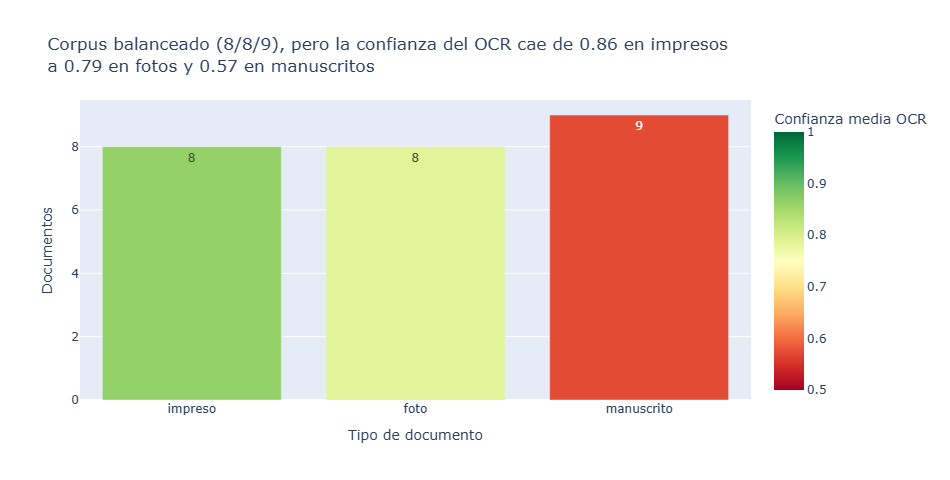

In [14]:
# PROCESO 6.1: Gráfico 1, documentos por tipo y calidad de lectura.
# Insumo: `docs`.
# Resultado: barras con el número de documentos por tipo, coloreadas por la confianza media del OCR.
por_tipo = (docs.groupby("tipo").agg(documentos=("id", "count"), confianza=("confianza_media", "mean"),
                                     caracteres=("n_caracteres", "median"))
            .reindex(["impreso", "foto", "manuscrito"]).reset_index())
c = por_tipo.set_index("tipo")["confianza"]
fig1 = px.bar(por_tipo, x="tipo", y="documentos", color="confianza", text="documentos",
              color_continuous_scale="RdYlGn", range_color=[0.5, 1.0],
              hover_data={"caracteres": True, "confianza": ":.2f"},
              labels={"tipo": "Tipo de documento", "documentos": "Documentos", "confianza": "Confianza media OCR"},
              title=(f"Corpus balanceado (8/8/9), pero la confianza del OCR cae de {c['impreso']:.2f} en impresos<br>"
                     f"a {c['foto']:.2f} en fotos y {c['manuscrito']:.2f} en manuscritos"))
mostrar(fig1, "grafico_1_documentos_por_tipo")

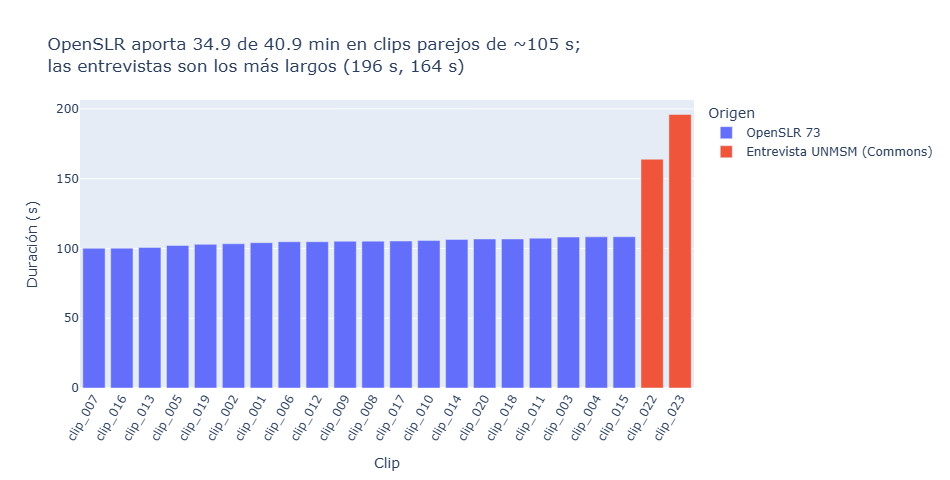

In [15]:
# PROCESO 6.2: Gráfico 2, duración por clip y origen.
# Insumo: `clips`.
# Resultado: barras de duración por clip, coloreadas por origen.
minutos = clips.groupby("origen")["duracion_seg"].sum() / 60
largo = clips.nlargest(2, "duracion_seg")
fig2 = px.bar(clips.sort_values("duracion_seg"), x="id", y="duracion_seg", color="origen",
              labels={"id": "Clip", "duracion_seg": "Duración (s)", "origen": "Origen"},
              title=(f"OpenSLR aporta {minutos['OpenSLR 73']:.1f} de {minutos.sum():.1f} min en clips parejos de ~105 s;<br>"
                     f"las entrevistas son los más largos ({', '.join(f'{d:.0f} s' for d in largo['duracion_seg'])})"))
fig2.update_xaxes(tickangle=-60)
mostrar(fig2, "grafico_2_duracion_clips")

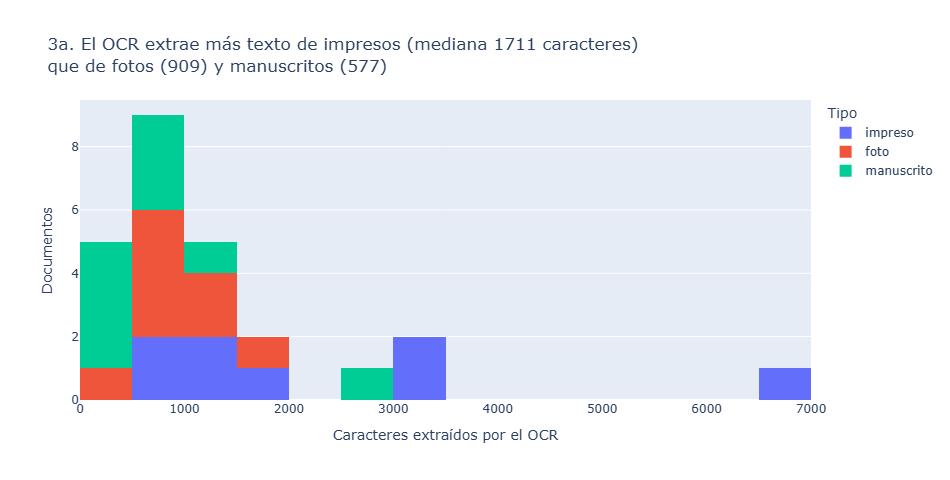

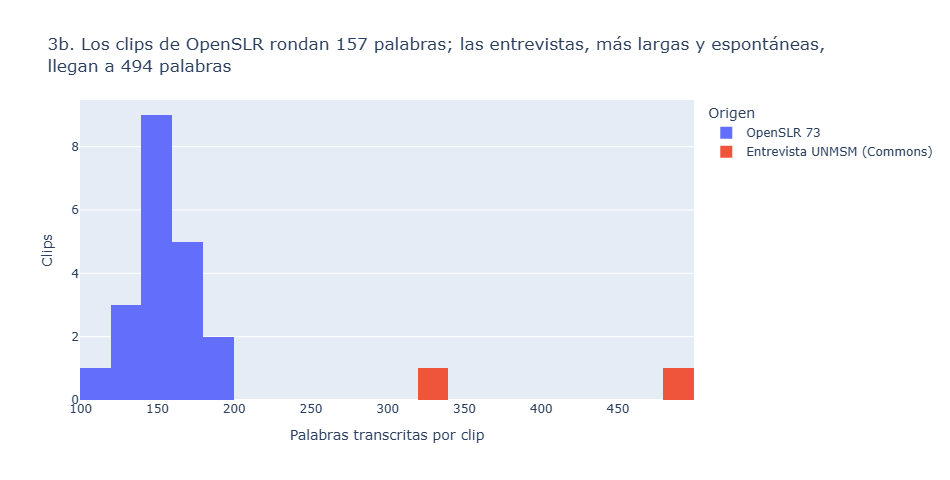

In [16]:
# PROCESO 6.3: Gráfico 3, longitud de los textos extraídos.
# Insumo: n_caracteres (OCR) y n_palabras (ASR).
# Resultado: dos histogramas (3a: caracteres OCR por tipo; 3b: palabras ASR por origen), cada uno con su propia escala.
med = docs.groupby("tipo")["n_caracteres"].median()
fig3a = px.histogram(docs, x="n_caracteres", color="tipo", nbins=14, barmode="stack",
                     category_orders={"tipo": ["impreso", "foto", "manuscrito"]},
                     labels={"n_caracteres": "Caracteres extraídos por el OCR", "tipo": "Tipo"},
                     title=(f"3a. El OCR extrae más texto de impresos (mediana {med['impreso']:.0f} caracteres)<br>"
                            f"que de fotos ({med['foto']:.0f}) y manuscritos ({med['manuscrito']:.0f})"))
fig3a.update_yaxes(title="Documentos")
mostrar(fig3a, "grafico_3a_longitud_ocr")

med_asr = clips.groupby("origen")["n_palabras"].median()
fig3b = px.histogram(clips, x="n_palabras", color="origen", nbins=20, barmode="stack",
                     labels={"n_palabras": "Palabras transcritas por clip", "origen": "Origen"},
                     title=(f"3b. Los clips de OpenSLR rondan {med_asr['OpenSLR 73']:.0f} palabras; las entrevistas, más largas "
                            f"y espontáneas,<br>llegan a {clips['n_palabras'].max():.0f} palabras"))
fig3b.update_yaxes(title="Clips")
mostrar(fig3b, "grafico_3b_longitud_asr")

## Proceso 7. Validación

Se revisan los extremos. Los textos más largos y más cortos deben coincidir con las colas de los histogramas, y su contenido debe tener sentido para el tipo de documento.

In [17]:
# PROCESO 7: Los 3 documentos con OCR más largo y más corto.
# Insumo: `docs`.
# Resultado: tabla con id, tipo, número de caracteres, confianza y el inicio del texto.
cols = ["id", "tipo", "n_caracteres", "confianza_media", "texto_inicio"]
docs["texto_inicio"] = docs["texto_ocr"].str.replace("\n", " ").str[:110]
display(docs.nlargest(3, "n_caracteres")[cols])
display(docs.nsmallest(3, "n_caracteres")[cols])

,id,tipo,n_caracteres,confianza_media,texto_inicio
3,doc_004,impreso,6513,0.652,"Eate peridion se lopacia ch esta Capkal Dari, drevas remitrae 4 la Impre Le svige q..."
1,doc_002,impreso,3104,0.983,Año IV Lima 9 de mayo de 1908 N. 10 PARIEDADE REVISTA SEMANAL ILUSTRADA Sucesora ...
2,doc_003,impreso,3095,0.982,"AñoVI Lima, 29 de enero de 1910 N.°100 REVISTA SEMANAL ILUSTRADE Sucesora de“PRISM..."


,id,tipo,n_caracteres,confianza_media,texto_inicio
22,doc_023,manuscrito,181,0.330,gal ma t aa m d a aa emmotncamiebalpoma tameen apor qede afmin s ...
11,doc_012,foto,273,0.857,"911 OLLENDORFF REFORMADO. GRAMÁTICA ta bo dad, LATINA, grado de foindor las Ha..."
21,doc_022,manuscrito,324,0.483,50 00 S0so wts4ow8v 80201802700800300 e0 w842000n002600 04000600665000063.8wm ...


In [18]:
# PROCESO 7.1: Los 3 clips más largos y más cortos.
# Insumo: `clips`.
# Resultado: tabla con duración, palabras, palabras por minuto e inicio de la transcripción.
clips["palabras_por_min"] = (clips["n_palabras"] / clips["duracion_seg"] * 60).round(0)
clips["texto_inicio"] = clips["texto_asr"].str[:110]
cols = ["id", "origen", "duracion_seg", "n_palabras", "palabras_por_min", "texto_inicio"]
display(clips.nlargest(3, "duracion_seg")[cols])
display(clips.nsmallest(3, "duracion_seg")[cols])

,id,origen,duracion_seg,n_palabras,palabras_por_min,texto_inicio
21,clip_023,Entrevista UNMSM (Commons),196.03,494,151.0,"[HABLANTE_1] Buenas noches, primeramente es mi nombre [PERSONA_1], soy estudiante de l..."
20,clip_022,Entrevista UNMSM (Commons),163.90,330,121.0,"[HABLANTE_1] Buenas noches, soy [PERSONA_1], estudiante de Los San Marcos, ¿cuál es su..."
14,clip_015,OpenSLR 73,108.37,167,92.0,Las teclas de la máquina de escribir necesitan estar muy desgastadas para la filmación...


,id,origen,duracion_seg,n_palabras,palabras_por_min,texto_inicio
6,clip_007,OpenSLR 73,100.10,147,88.0,¿Has volado en avioneta? ¿Quién subió el mejor video? ¿A qué edad debo vacunar a mis h...
15,clip_016,OpenSLR 73,100.18,136,81.0,te recomiendo que veas las películas de Luis Buñuel. Quiero llevar a mis visitas a un ...
12,clip_013,OpenSLR 73,100.69,160,95.0,¿Quiere que adquiera algún tipo de boleto o reservación? ¿Tengo que pasar alguna prueb...


## Proceso 8. Exportación

**Archivos que se generan:**
- `datos/documentos.csv` y `datos/transcripciones.csv`, con las columnas obligatorias y algunas columnas de apoyo.
- `datos/fuentes.csv`, con una fila por archivo del corpus final.
- `texto_referencia` queda vacío por ahora y se completa en la Parte 2.
- `datos/ejemplos/` guarda la muestra publicable: miniaturas de los 25 documentos (todos son de dominio público o tienen licencia libre con atribución) y 30 s de 3 clips de OpenSLR (CC BY-SA 4.0, hablantes anónimos). Las entrevistas no se incluyen como audio porque la voz de una persona privada no se puede seudonimizar; en el dashboard aparecen solo como texto seudonimizado.

In [19]:
# PROCESO 8: Exportar los tres CSV obligatorios.
# Insumo: `docs`, `clips` y fuentes_descarga.csv.
# Resultado: datos/documentos.csv, datos/transcripciones.csv y datos/fuentes.csv.
docs["texto_referencia"] = ""
clips["texto_referencia"] = ""
clips["idioma"] = "es"
clips["modelo_asr"] = MODELO_ASR

documentos_csv = docs[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia",
                       "titulo", "licencia", "pagina_commons", "n_lineas", "n_caracteres", "confianza_media",
                       "segundos_ocr", "entidades_reemplazadas"]]
transcripciones_csv = clips[["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes",
                             "texto_referencia", "origen", "fuente", "licencia", "n_palabras", "segundos_asr",
                             "factor_tiempo_real", "proporcion_voz", "entidades_reemplazadas"]]
fuentes_csv = fuentes_descarga[fuentes_descarga["id"].isin(set(docs["id"]) | set(clips["id"]))]

documentos_csv.to_csv(DATOS / "documentos.csv", index=False, encoding="utf-8")
transcripciones_csv.to_csv(DATOS / "transcripciones.csv", index=False, encoding="utf-8")
fuentes_csv.to_csv(DATOS / "fuentes.csv", index=False, encoding="utf-8")
descartes.to_csv(DATOS / "descartes.csv", index=False, encoding="utf-8")
for nombre, tabla in [("documentos.csv", documentos_csv), ("transcripciones.csv", transcripciones_csv), ("fuentes.csv", fuentes_csv)]:
    print(f"{nombre:22s} shape = {tabla.shape}")

documentos.csv         shape = (25, 15)
transcripciones.csv    shape = (22, 16)
fuentes.csv            shape = (47, 5)


In [20]:
# PROCESO 8.1: Primeras 5 filas de cada corpus.
display(documentos_csv.head(5))
display(transcripciones_csv.head(5))
display(fuentes_csv.head(5))

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,titulo,licencia,pagina_commons,n_lineas,n_caracteres,confianza_media,segundos_ocr,entidades_reemplazadas
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (PD-Peru-organization),"N1-1+ \nAño IV \nLima, 29 de febrero de 1908 \nProspecto \n \n \n--L \nREVISTA SEMANAL...","PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, orientación on, CPU, lado ≤ 2000 px)",,Variedades No. 0 (Número Prospecto).pdf,PD-Peru-organization,https://commons.wikimedia.org/wiki/File:Variedades_No._0_%28N%C3%BAmero_Prospecto%29.pdf,41,1947,0.871,38.83,0
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (PD-Peru-organization + PD-US),Año IV \nLima 9 de mayo de 1908 \nN. 10 \nPARIEDADE \nREVISTA SEMANAL ILUSTRADA \nSuce...,"PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, orientación on, CPU, lado ≤ 2000 px)",,Variedades No. 10.pdf,PD-Peru-organization + PD-US,https://commons.wikimedia.org/wiki/File:Variedades_No._10.pdf,84,3104,0.983,64.63,0
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (PD-Peru-organization),"AñoVI \nLima, 29 de enero de 1910 \nN.°100 \nREVISTA SEMANAL ILUSTRADE \nSucesora de“P...","PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, orientación on, CPU, lado ≤ 2000 px)",,Variedades No. 100.pdf,PD-Peru-organization,https://commons.wikimedia.org/wiki/File:Variedades_No._100.pdf,85,3095,0.982,67.77,0
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Wikimedia Commons (PD-old-100),"Eate peridion se \nlopacia ch esta Capkal \nDari, drevas remitrae 4 la Impre \nLe svig...","PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, orientación on, CPU, lado ≤ 2000 px)",,El Comercio Issue 1.jpg,PD-old-100,https://commons.wikimedia.org/wiki/File:El_Comercio_Issue_1.jpg,192,6513,0.652,111.98,0
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Wikimedia Commons (PD-old-100),"EL LIBERTADOR BAMON GASTILLA, \nGRAN MARISCAL DELOS EJERCITOS, \nCONDECORADO-CON LAS M...","PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, orientación on, CPU, lado ≤ 2000 px)",,Constitución Política del Perú (1856).pdf,PD-old-100,https://commons.wikimedia.org/wiki/File:Constituci%C3%B3n_Pol%C3%ADtica_del_Per%C3%BA_...,42,752,0.679,25.71,0


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,origen,fuente,licencia,n_palabras,segundos_asr,factor_tiempo_real,proporcion_voz,entidades_reemplazadas
0,clip_001,datos/raw/audio/clip_001.wav,104.11,es,¿Me puedes confirmar si ya está hecha la reservación? Ese mismo actor estuvo nominado ...,"faster-whisper small (int8, CPU, VAD Silero on, beam 5, es)",1,,OpenSLR 73,"OpenSLR 73 (es_pe_female.zip), hablante pef_06136, 11 enunciados concatenados",CC BY-SA 4.0,133,19.19,0.184,0.476,0
1,clip_002,datos/raw/audio/clip_002.wav,103.34,es,Necesito armar una conferencia y la verdad no sabría muy bien cómo hacerlo. La tempera...,"faster-whisper small (int8, CPU, VAD Silero on, beam 5, es)",1,,OpenSLR 73,"OpenSLR 73 (es_pe_male.zip), hablante pem_07508, 12 enunciados concatenados",CC BY-SA 4.0,116,18.57,0.180,0.347,0
2,clip_003,datos/raw/audio/clip_003.wav,108.12,es,"Hay fútbol femenino en Brasil, en Esgrima tenemos a tres campeonas. ¿Quién subió el me...","faster-whisper small (int8, CPU, VAD Silero on, beam 5, es)",1,,OpenSLR 73,"OpenSLR 73 (es_pe_female.zip), hablante pef_08784, 17 enunciados concatenados",CC BY-SA 4.0,126,20.37,0.188,0.427,0
3,clip_004,datos/raw/audio/clip_004.wav,108.29,es,El otro día comí un helado gigante mientras veía una película. Puedes verificarse algú...,"faster-whisper small (int8, CPU, VAD Silero on, beam 5, es)",1,,OpenSLR 73,"OpenSLR 73 (es_pe_male.zip), hablante pem_08784, 15 enunciados concatenados",CC BY-SA 4.0,160,28.92,0.267,0.528,0
4,clip_005,datos/raw/audio/clip_005.wav,102.06,es,Uno de los beneficios de andar en bicicleta es que es muy buen ejercicio. ¿Qué pasó en...,"faster-whisper small (int8, CPU, VAD Silero on, beam 5, es)",1,,OpenSLR 73,"OpenSLR 73 (es_pe_female.zip), hablante pef_01523, 14 enunciados concatenados",CC BY-SA 4.0,152,22.43,0.220,0.477,0


,id,modalidad,fuente_url,licencia,acceso
0,doc_001,documento,https://upload.wikimedia.org/wikipedia/commons/thumb/4/4e/Variedades_No._0_%28N%C3%BAm...,PD-Peru-organization,"Wikimedia Commons, descarga directa; ficha: https://commons.wikimedia.org/wiki/File:Va..."
1,doc_002,documento,https://upload.wikimedia.org/wikipedia/commons/thumb/c/ce/Variedades_No._10.pdf/page3-...,PD-Peru-organization + PD-US,"Wikimedia Commons, descarga directa; ficha: https://commons.wikimedia.org/wiki/File:Va..."
2,doc_003,documento,https://upload.wikimedia.org/wikipedia/commons/thumb/2/22/Variedades_No._100.pdf/page5...,PD-Peru-organization,"Wikimedia Commons, descarga directa; ficha: https://commons.wikimedia.org/wiki/File:Va..."
3,doc_004,documento,https://upload.wikimedia.org/wikipedia/commons/0/0e/El_Comercio_Issue_1.jpg,PD-old-100,"Wikimedia Commons, descarga directa; ficha: https://commons.wikimedia.org/wiki/File:El..."
4,doc_005,documento,https://upload.wikimedia.org/wikipedia/commons/thumb/e/e1/Constituci%C3%B3n_Pol%C3%ADt...,PD-old-100,"Wikimedia Commons, descarga directa; ficha: https://commons.wikimedia.org/wiki/File:Co..."


In [21]:
# PROCESO 8.2: Muestra publicable para el dashboard.
# Insumo: imágenes originales y 3 clips de OpenSLR.
# Resultado: miniaturas JPG (lado ≤ 900 px) y fragmentos OGG de 30 s en datos/ejemplos/.

# numpy: recorta el arreglo de audio a los primeros 30 s.
import numpy as np

for _, fila in docs.iterrows():
    destino = EJEMPLOS / f"{fila['id']}.jpg"
    if not destino.exists():
        with Image.open(BASE / fila["archivo"]) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            im.thumbnail((900, 900))
            im.save(destino, quality=80)
for clip_id in ["clip_001", "clip_002", "clip_003"]:
    audio = voz.cargar_audio(BASE / f"datos/raw/audio/{clip_id}.wav")[: 30 * voz.SR]
    sf.write(EJEMPLOS / f"{clip_id}_30s.ogg", audio.astype(np.float32), voz.SR, format="OGG", subtype="VORBIS")
peso = sum(p.stat().st_size for p in EJEMPLOS.iterdir()) / 1e6
print(f"{len(list(EJEMPLOS.iterdir()))} archivos en datos/ejemplos/ ({peso:.1f} MB)")

32 archivos en datos/ejemplos/ (3.4 MB)
